In [28]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

bits = 4
bits_str = str(bits)

In [29]:
from evaluation.fixed_points      import fixed_ponts

number_of_owns = 25
own_sboxes_index = range(1,number_of_owns+1)

selected = []

for i in own_sboxes_index:
    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"    
        sbox = SBox(n_in, n_out, table, name)                    
        fijos = fixed_ponts(sbox, detail=True)[1]
        if fijos == 0:
            selected.append(i)
print(f"{selected}")

[1, 3, 5, 12, 14, 19, 20, 21]


In [30]:
selected = [1, 3, 12, 14, 20, 21]

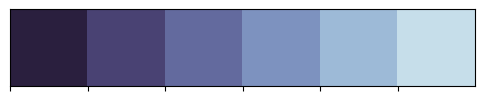

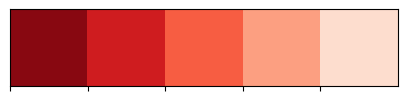

In [31]:
number_of_owns = len(selected)
own_sboxes_index = selected

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=14)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [32]:
to_proof = ["02_elefant", "03_GIFT-COFB", "06_PHOTON-Beetle", "present"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: ELEFANT (4x4)
Procesando S-Box: Grain-128AEAD (4x4)
Procesando S-Box: PHOTON-Beetle (4x4)
Procesando S-Box: PRESENT (4x4)


In [33]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


6 S-Boxes cargadas desde data.json


In [34]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [35]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,16)),
    log_scale=True,
    detail=False
)
chart_tv

alt.Chart(...)

In [36]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |   ELEFANT |   Grain-128AEAD |   PHOTON-Beetle |   PRESENT |   Variant #1 |   Variant #12 |   Variant #14 |   Variant #20 |   Variant #21 |   Variant #3 |
|----:|----------:|----------------:|----------------:|----------:|-------------:|--------------:|--------------:|--------------:|--------------:|-------------:|
|   1 | 0.25      |       0.375     |       0.25      | 0.25      |    0.25      |     0.25      |     0.25      |     0.25      |     0.25      |    0.25      |
|   2 | 0.125     |       0.15625   |       0.15625   | 0.15625   |    0.15625   |     0.15625   |     0.15625   |     0.15625   |     0.125     |    0.109375  |
|   3 | 0.09375   |       0.0957031 |       0.09375   | 0.09375   |    0.0957031 |     0.0878906 |     0.0898438 |     0.09375   |     0.0917969 |    0.0878906 |
|   4 | 0.078125  |       0.0776367 |       0.0791016 | 0.0791016 |    0.0771484 |     0.074707  |     0.0742188 |     0.0751953 |     0.0715332 |    0.0744629 |
|   5 | 0.0698242 |       0.

alt.Chart(...)

In [37]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_mix

[0.1, 0.01, 0.001, 0.0001, 1e-05, 1e-06, 1e-07, 1e-08, 1e-09]


alt.Chart(...)

In [38]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_spec

alt.Chart(...)

# Clasicas


=== Métricas de S-Boxes ===
         name  uniformity  max_ddt  fixed_points  non_linearity  avg_sac  max_std_sac
      ELEFANT           4       16             0            4.0 0.656250     0.216506
Grain-128AEAD           6       16             0            4.0 0.625000     0.279508
PHOTON-Beetle           4       16             0            4.0 0.625000     0.216506
      PRESENT           4       16             0            4.0 0.625000     0.216506
   Variant #1           4       16             0            4.0 0.531250     0.125000
   Variant #3           4       16             0            4.0 0.531250     0.207289
  Variant #12           4       16             0            4.0 0.484375     0.207289
  Variant #14           4       16             0            4.0 0.515625     0.176777
  Variant #20           4       16             0            4.0 0.546875     0.207289
  Variant #21           4       16             0            4.0 0.562500     0.207289


c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


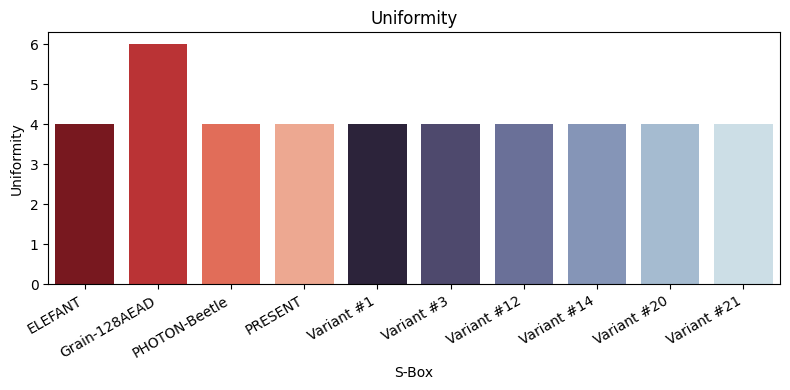

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


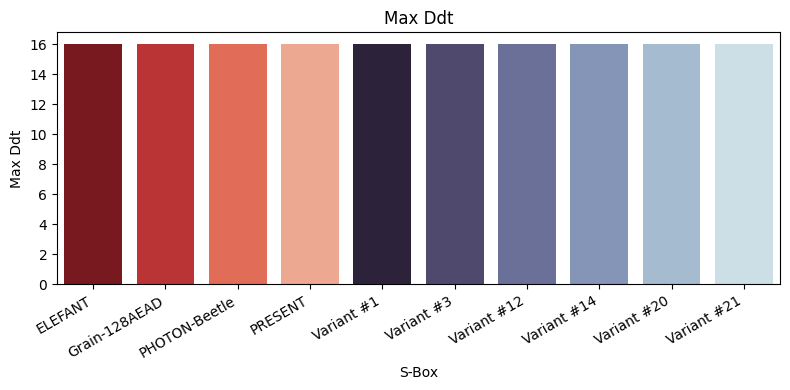

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


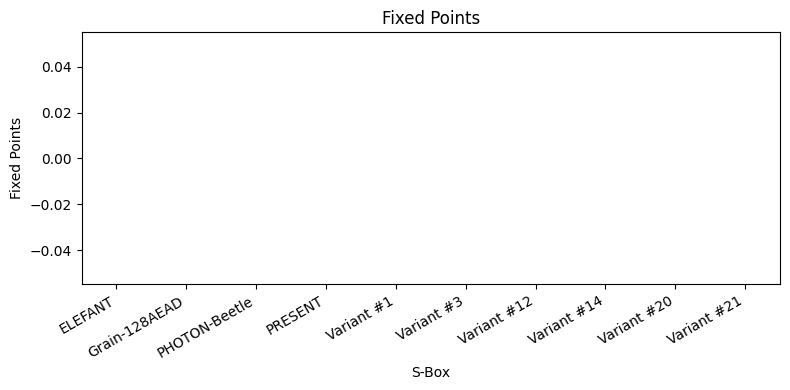

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


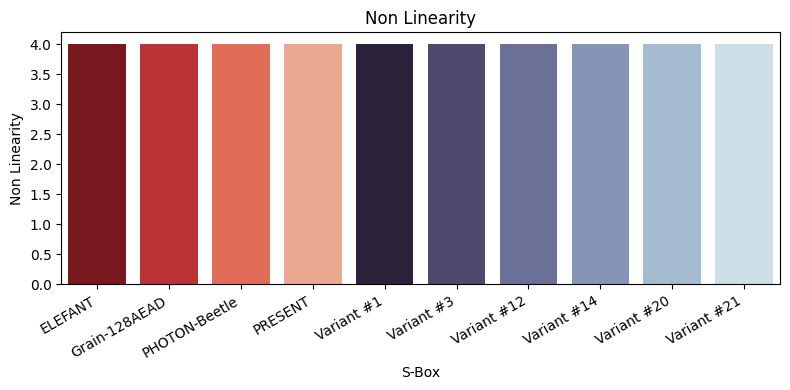

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


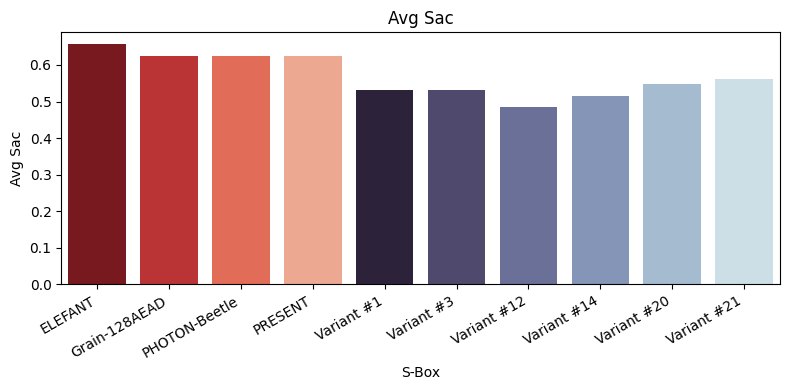

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


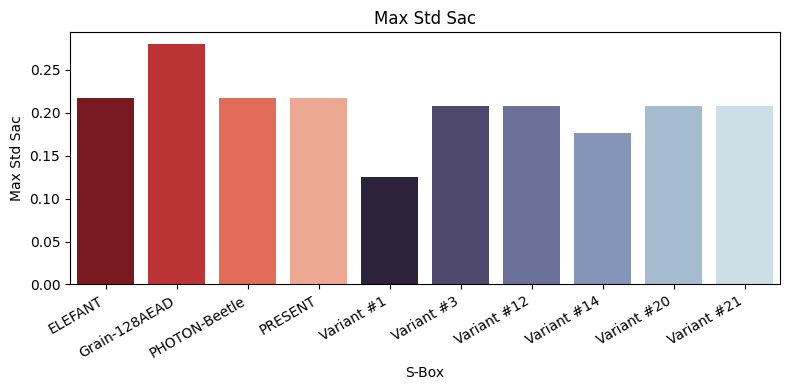

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,ELEFANT,4,16,0,4.0,0.656250,0.216506
1,Grain-128AEAD,6,16,0,4.0,0.625000,0.279508
2,PHOTON-Beetle,4,16,0,4.0,0.625000,0.216506
3,PRESENT,4,16,0,4.0,0.625000,0.216506
4,Variant #1,4,16,0,4.0,0.531250,0.125000
5,Variant #3,4,16,0,4.0,0.531250,0.207289
6,Variant #12,4,16,0,4.0,0.484375,0.207289
7,Variant #14,4,16,0,4.0,0.515625,0.176777
8,Variant #20,4,16,0,4.0,0.546875,0.207289
9,Variant #21,4,16,0,4.0,0.562500,0.207289


In [39]:
from evaluation.sbox_metrics_analysis import run_all_metrics

run_all_metrics(specs)

# Ranking

In [40]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

print(to_display.to_markdown(index=False))
#import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


| name        |   total_rank |   non_linearity |   uniformity |   fixed_points |   avg_sac |   max_ddt |   max_std_sac |
|:------------|-------------:|----------------:|-------------:|---------------:|----------:|----------:|--------------:|
| Variant #14 |         25   |               4 |            4 |              0 |  0.515625 |        16 |      0.176777 |
| Variant #1  |         26   |               4 |            4 |              0 |  0.53125  |        16 |      0.125    |
| Variant #12 |         27.5 |               4 |            4 |              0 |  0.484375 |        16 |      0.207289 |
| Variant #3  |         29.5 |               4 |            4 |              0 |  0.53125  |        16 |      0.207289 |
| Variant #20 |         31   |               4 |            4 |              0 |  0.546875 |        16 |      0.207289 |
